# 12 · Time Series Forecasting

Sales next week, electricity demand tomorrow, server load in the next hour: whenever data arrives **in order over time** and you want to predict the future, you have a time series problem. The tools from earlier notebooks still apply, but the time order changes several rules. Most importantly: **you can never let the future leak into the past.**

**What you'll learn**
1. What makes time series different: order, **autocorrelation**, trend and seasonality
2. **Decomposing** a series into trend + seasonality + remainder (moving averages, STL)
3. **Stationarity** and **differencing**
4. **Autocorrelation (ACF/PACF)** — 🐍 pure Python → 🔢 NumPy → 📦 statsmodels
5. Honest evaluation: time-ordered splits, **walk-forward validation**, MAE/RMSE/MAPE/**MASE**
6. **Baselines** that are surprisingly hard to beat (naive, seasonal naive)
7. Classical models: **exponential smoothing** / Holt-Winters, **AR**, **ARIMA / SARIMA**
8. The ML approach: **lag features**, rolling statistics, calendar features, gradient boosting — and its leakage traps
9. **Multi-step** forecasting (recursive vs direct) and **prediction intervals**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math, warnings
plt.rcParams["figure.figsize"] = (11, 3.4)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
warnings.filterwarnings("ignore")      # statsmodels is chatty about convergence and frequency

## 1. The data: three years of daily store sales

We generate a realistic series with known ingredients, so we can check whether each method recovers them:
- an upward **trend** (the store grows),
- a **weekly** pattern (weekends are busy),
- a **yearly** pattern (a December peak),
- a few **holiday** spikes,
- and **autocorrelated** noise (a good day tends to be followed by another good day).

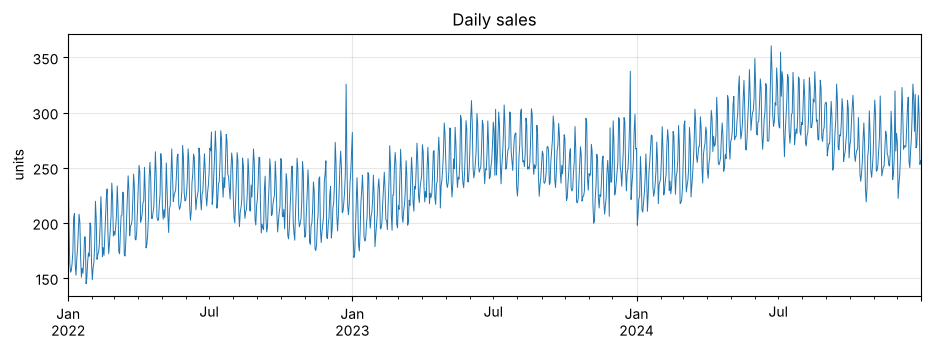

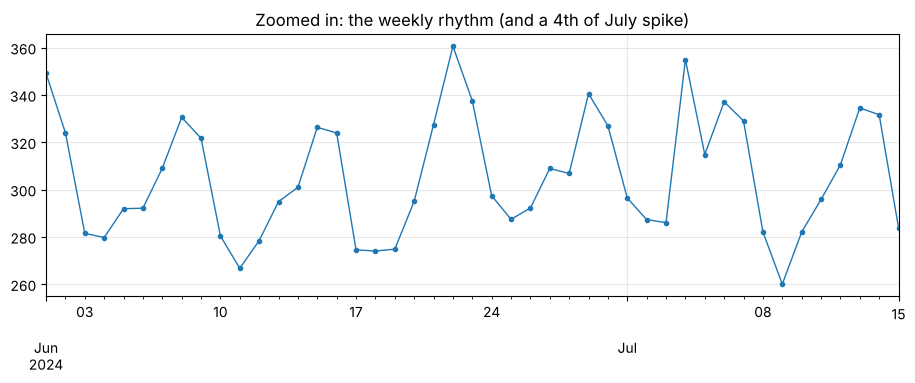

In [2]:
rng = np.random.default_rng(7)
dates = pd.date_range("2022-01-01", "2024-12-31", freq="D")
n = len(dates); t = np.arange(n)

trend = 200 + 0.08 * t
weekly = np.array([-15, -20, -12, -5, 10, 35, 25])[dates.dayofweek]          # Mon..Sun
yearly = 25 * np.sin(2 * np.pi * (dates.dayofyear - 80) / 365.25) + 30 * np.exp(-((dates.dayofyear - 355) / 12) ** 2)
holiday = np.where(dates.strftime("%m-%d").isin(["01-01", "07-04", "11-28", "12-24"]), 60, 0)
noise = np.zeros(n)
for i in range(1, n):
    noise[i] = 0.6 * noise[i - 1] + rng.normal(0, 8)                          # AR(1) noise
sales = pd.Series(trend + weekly + yearly + holiday + noise, index=dates, name="sales").round(1)

sales.plot(lw=0.7); plt.title("Daily sales"); plt.ylabel("units"); plt.show()
sales["2024-06-01":"2024-07-15"].plot(marker=".", lw=1); plt.title("Zoomed in: the weekly rhythm (and a 4th of July spike)"); plt.show()

## 2. What's different about time series?

| Ordinary ML | Time series |
|---|---|
| rows are independent | each value depends on recent values (**autocorrelation**) |
| shuffle + random split | **never shuffle**; train on the past, test on the future |
| features describe the row | the main features are **the series' own past** |
| predict one target | often predict **many steps ahead** |

## 3. Decomposition: trend + seasonality + remainder

An **additive** model: $y_t = T_t + S_t + R_t$ (use **multiplicative**, $y_t = T_t \times S_t \times R_t$, when seasonal swings grow with the level — or take logs, which turns it additive).

**Trend by moving average:** average a window as wide as the season (7 days), so each weekday appears once and the weekly pattern cancels out.

pure Python == NumPy: True


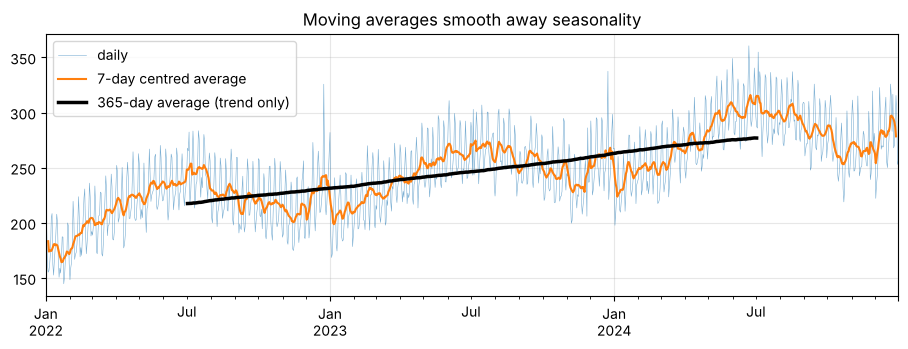

In [3]:
# 🐍 Pure Python centred moving average
def moving_average_python(values, window):
    half = window // 2; out = []
    for i in range(len(values)):
        if i < half or i >= len(values) - half:
            out.append(None)                       # not enough neighbours at the edges
        else:
            out.append(sum(values[i - half:i + half + 1]) / window)
    return out

ma_py = moving_average_python(sales.tolist(), 7)

# 🔢 NumPy: a moving average is a convolution with a flat kernel
ma_np = np.convolve(sales.to_numpy(), np.ones(7) / 7, mode="valid")
print("pure Python == NumPy:", np.allclose([v for v in ma_py if v is not None], ma_np))

# 📦 pandas
ma_pd = sales.rolling(7, center=True).mean()
sales.plot(lw=0.4, alpha=0.6, label="daily"); ma_pd.plot(lw=1.5, label="7-day centred average")
sales.rolling(365, center=True).mean().plot(lw=2.5, c="k", label="365-day average (trend only)")
plt.legend(); plt.title("Moving averages smooth away seasonality"); plt.show()

In [4]:
# Classical decomposition by hand: trend = moving average; seasonal = average detrended value per weekday
detrended = sales - sales.rolling(7, center=True).mean()
weekday_effect = detrended.groupby(sales.index.dayofweek).mean()
weekday_effect -= weekday_effect.mean()
print("estimated weekday effects (Mon..Sun):", weekday_effect.round(1).tolist())
print("true weekday effects (centred):      ", (np.array([-15, -20, -12, -5, 10, 35, 25]) - np.mean([-15, -20, -12, -5, 10, 35, 25])).round(1).tolist())

estimated weekday effects (Mon..Sun): [-17.2, -22.1, -15.6, -6.9, 6.6, 32.6, 22.6]
true weekday effects (centred):       [-17.6, -22.6, -14.6, -7.6, 7.4, 32.4, 22.4]


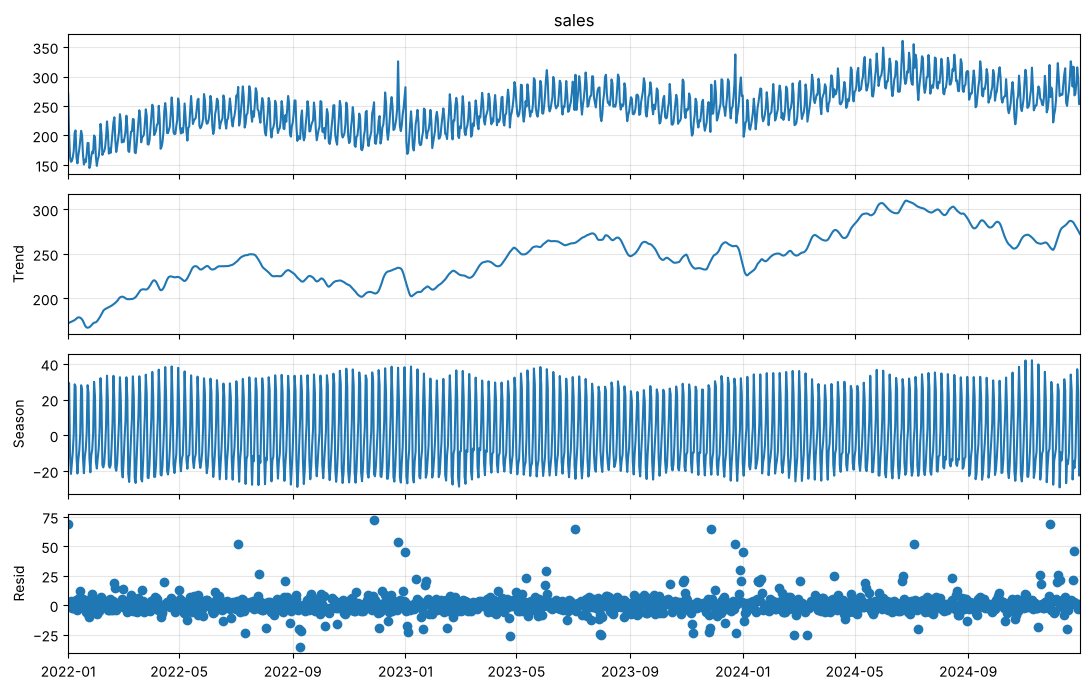

In [5]:
# 📦 STL (Seasonal-Trend decomposition using Loess) — robust and flexible; the standard tool
from statsmodels.tsa.seasonal import STL
res = STL(sales, period=7, robust=True).fit()
fig = res.plot(); fig.set_size_inches(11, 7); plt.tight_layout(); plt.show()

STL with `period=7` splits out the weekly pattern; the yearly pattern stays in the "trend" component (you can run STL again on it with period 365, or use `MSTL` for multiple seasonalities). The remainder shows the holiday spikes as outliers.

## 4. Stationarity and differencing

A series is (weakly) **stationary** if its mean, variance and autocorrelation don't change over time. Many classical models (AR, ARMA) assume it. Trend and seasonality break it.

The fix: **differencing**.
- First difference $y_t - y_{t-1}$ removes a linear trend.
- Seasonal difference $y_t - y_{t-7}$ removes a weekly pattern.

The **Augmented Dickey-Fuller (ADF) test** checks for a "unit root" (a random-walk-like, non-stationary component). Small p-value → evidence the series is stationary.

original                   ADF p-value = 0.1145
first difference           ADF p-value = 0.0000
weekly difference          ADF p-value = 0.0000
weekly + first difference  ADF p-value = 0.0000


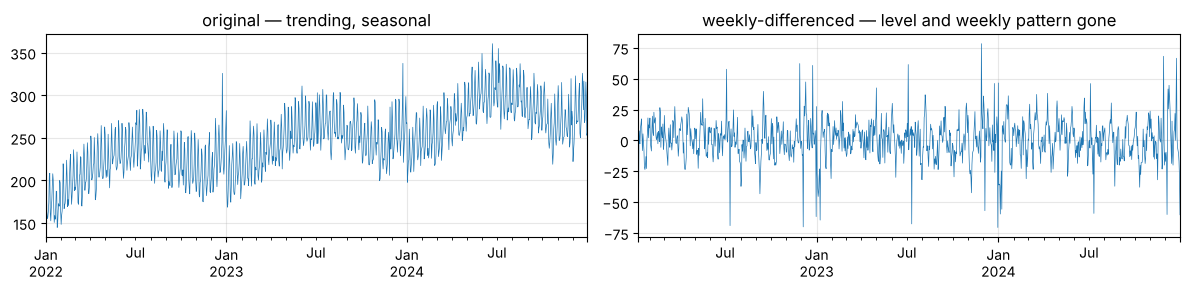

In [6]:
from statsmodels.tsa.stattools import adfuller
diff1 = sales.diff().dropna()
diff7 = sales.diff(7).dropna()
diff_both = sales.diff(7).diff().dropna()
for name, s in [("original", sales), ("first difference", diff1), ("weekly difference", diff7), ("weekly + first difference", diff_both)]:
    print(f"{name:26s} ADF p-value = {adfuller(s, autolag='AIC')[1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
sales.plot(ax=ax[0], lw=0.5, title="original — trending, seasonal")
diff7.plot(ax=ax[1], lw=0.5, title="weekly-differenced — level and weekly pattern gone"); plt.tight_layout(); plt.show()

The trend is slow relative to the noise, so ADF already calls the original "stationary" — tests have limited power; **always look at the plot too**. Differencing clearly removes the trend and weekly cycle.

## 5. Autocorrelation: ACF and PACF

The **autocorrelation at lag k** is the correlation between the series and itself shifted by k steps:
$$ \rho_k = \frac{\sum_{t=k+1}^{n} (y_t - \bar y)(y_{t-k} - \bar y)}{\sum_{t=1}^{n} (y_t - \bar y)^2} $$
The **ACF** plots $\rho_k$ for many k. The **PACF** (partial autocorrelation) shows the correlation at lag k *after removing* the effect of the shorter lags — it tells you how many past values directly matter.

How to read them:
- Spikes at 7, 14, 21… → weekly seasonality.
- ACF decays slowly → trend / non-stationarity (difference it).
- PACF cuts off after lag p → an **AR(p)** model fits.

pure Python == NumPy == statsmodels: True True


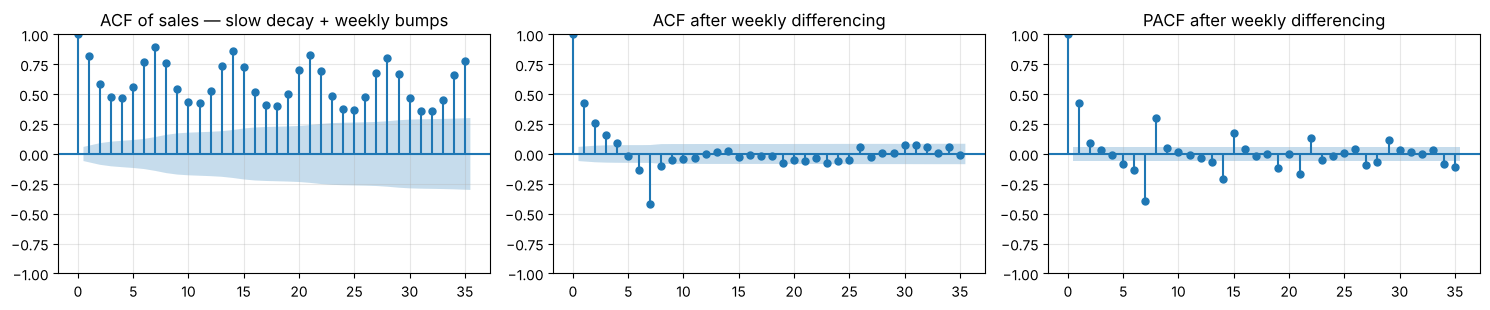

In [7]:
# 🐍 Pure Python ACF
def acf_python(values, max_lag):
    n = len(values); mean = sum(values) / n
    denom = sum((v - mean) ** 2 for v in values)
    return [sum((values[t] - mean) * (values[t - k] - mean) for t in range(k, n)) / denom for k in range(max_lag + 1)]

# 🔢 NumPy ACF
def acf_numpy(y, max_lag):
    y = np.asarray(y, float) - np.mean(y); denom = y @ y
    return np.array([y[k:] @ y[:len(y) - k] / denom for k in range(max_lag + 1)])

from statsmodels.tsa.stattools import acf
a_py = acf_python(diff1.tolist(), 21); a_np = acf_numpy(diff1, 21); a_sm = acf(diff1, nlags=21)
print("pure Python == NumPy == statsmodels:", np.allclose(a_py, a_np), np.allclose(a_np, a_sm))

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
plot_acf(sales, lags=35, ax=ax[0], title="ACF of sales — slow decay + weekly bumps")
plot_acf(diff7, lags=35, ax=ax[1], title="ACF after weekly differencing")
plot_pacf(diff7, lags=35, ax=ax[2], title="PACF after weekly differencing", method="ywm")
plt.tight_layout(); plt.show()

## 6. Honest evaluation for time series

**Split by time.** We hold out the last 90 days as the test period.

**Metrics:**
| Metric | Formula | Notes |
|---|---|---|
| MAE | mean \|y − ŷ\| | same units as y; robust |
| RMSE | √mean (y − ŷ)² | punishes big misses |
| MAPE | mean \|y − ŷ\| / \|y\| | percent — but explodes near y = 0 |
| **MASE** | MAE / MAE of the seasonal-naive forecast (in-sample) | **< 1 beats the naive baseline**; comparable across series |

In [8]:
test_days = 90
train, test = sales.iloc[:-test_days], sales.iloc[-test_days:]

def mase_scale(train_series, m=7):
    return np.mean(np.abs(np.asarray(train_series)[m:] - np.asarray(train_series)[:-m]))
SCALE = mase_scale(train)

def evaluate(name, forecast, actual=test, table=[]):
    f, a = np.asarray(forecast), np.asarray(actual)
    row = {"model": name, "MAE": np.mean(np.abs(a - f)), "RMSE": np.sqrt(np.mean((a - f) ** 2)),
           "MAPE %": 100 * np.mean(np.abs(a - f) / np.abs(a)), "MASE": np.mean(np.abs(a - f)) / SCALE}
    table.append(row)
    return pd.DataFrame(table).set_index("model").round(2)
print(f"train {train.index[0].date()} → {train.index[-1].date()} ({len(train)} days) | test {test.index[0].date()} → {test.index[-1].date()}")

train 2022-01-01 → 2024-10-02 (1006 days) | test 2024-10-03 → 2024-12-31


## 7. Baselines — always start here

- **Naive:** tomorrow = today (for every future day: the last observed value).
- **Seasonal naive:** next Monday = last Monday.
- **Mean:** the historical average.
- **Drift:** extend the line from the first to the last observation.

Complex models frequently fail to beat seasonal naive. If yours doesn't, it isn't ready.

In [9]:
# 🐍 Pure Python baselines for an h-step forecast
def naive_forecast(history, h):            return [history[-1]] * h
def seasonal_naive_forecast(history, h, m=7): return [history[-m + (i % m)] for i in range(h)]
def mean_forecast(history, h):             return [sum(history) / len(history)] * h
def drift_forecast(history, h):
    slope = (history[-1] - history[0]) / (len(history) - 1)
    return [history[-1] + slope * (i + 1) for i in range(h)]

hist = train.tolist()
baselines = {"naive": naive_forecast(hist, test_days), "seasonal naive": seasonal_naive_forecast(hist, test_days),
             "mean": mean_forecast(hist, test_days), "drift": drift_forecast(hist, test_days)}
for name, f in baselines.items():
    table = evaluate(name, f)
table

,MAE,RMSE,MAPE %,MASE
model,,,,
naive,21.23,25.21,7.91,1.82
seasonal naive,16.73,20.08,6.36,1.43
mean,29.35,36.80,10.21,2.52
drift,21.26,25.21,7.92,1.82


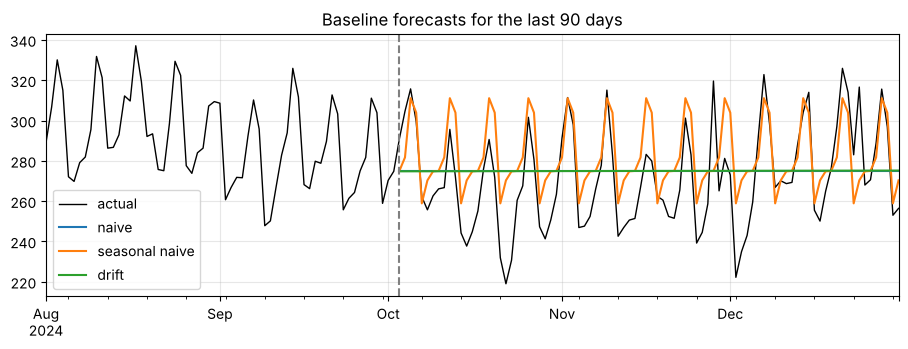

In [10]:
ax = sales["2024-08-01":].plot(c="k", lw=1, label="actual")
for name in ["naive", "seasonal naive", "drift"]:
    pd.Series(baselines[name], index=test.index).plot(ax=ax, label=name)
ax.axvline(test.index[0], ls="--", c="gray"); plt.legend(); plt.title("Baseline forecasts for the last 90 days"); plt.show()

## 8. Exponential smoothing

**Simple exponential smoothing (SES):** the forecast is a weighted average of the past, with weights that **decay exponentially** — recent days count most:
$$ \ell_t = \alpha\,y_t + (1-\alpha)\,\ell_{t-1}, \qquad \hat y_{t+h} = \ell_t $$
α near 1 → reacts fast (like naive); α near 0 → very smooth (like the mean).

**Holt-Winters** adds a **trend** term and a **seasonal** term, each with its own smoothing parameter — a strong, cheap classical model.

In [11]:
# 🐍 Pure Python SES, and choosing α by minimising one-step-ahead squared error
def ses_python(values, alpha):
    level = values[0]; one_step_errors = []
    for v in values[1:]:
        one_step_errors.append(v - level)                 # forecast for this step was the previous level
        level = alpha * v + (1 - alpha) * level
    return level, sum(e * e for e in one_step_errors)

best_alpha = min((a / 100 for a in range(1, 100)), key=lambda a: ses_python(hist, a)[1])
level, _ = ses_python(hist, best_alpha)
print(f"best α = {best_alpha:.2f}, final level = {level:.1f}")
table = evaluate("simple exp. smoothing (ours)", [level] * test_days)

# 📦 statsmodels Holt-Winters: additive trend + additive weekly seasonality
from statsmodels.tsa.holtwinters import ExponentialSmoothing
hw = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=7).fit()
hw_fc = hw.forecast(test_days)
print("Holt-Winters smoothing params:", {k: round(v, 3) for k, v in hw.params.items() if k in ("smoothing_level", "smoothing_trend", "smoothing_seasonal")})
table = evaluate("Holt-Winters", hw_fc)
table

best α = 0.99, final level = 274.8


Holt-Winters smoothing params: {'smoothing_level': np.float64(0.425), 'smoothing_trend': np.float64(0.0), 'smoothing_seasonal': np.float64(0.0)}


,MAE,RMSE,MAPE %,MASE
model,,,,
naive,21.23,25.21,7.91,1.82
seasonal naive,16.73,20.08,6.36,1.43
mean,29.35,36.80,10.21,2.52
drift,21.26,25.21,7.92,1.82
simple exp. smoothing (ours),21.22,25.20,7.91,1.82
Holt-Winters,21.53,24.65,8.19,1.85


## 9. Autoregressive models: AR, ARIMA, SARIMA

**AR(p):** today is a linear combination of the last p days plus noise:
$$ y_t = c + \phi_1 y_{t-1} + \phi_2 y_{t-2} + \dots + \phi_p y_{t-p} + \varepsilon_t $$
That's just **linear regression on lagged copies of the series** — so we can fit it with least squares (notebook 01).

**ARIMA(p, d, q)** = AR(p) on the series differenced d times, plus **MA(q)** terms (regression on past *forecast errors*). **SARIMA** adds seasonal versions of each: (P, D, Q)ₘ.

In [12]:
# 🔢 AR(p) by least squares in NumPy, on the weekly-differenced series
def lag_matrix(y, p):
    return np.column_stack([np.ones(len(y) - p)] + [y[p - k:len(y) - k] for k in range(1, p + 1)])

def fit_ar(y, p):
    A = lag_matrix(y, p); target = y[p:]
    return np.linalg.lstsq(A, target, rcond=None)[0]       # [c, φ1..φp]

def forecast_ar(y, coef, h):
    p = len(coef) - 1; hist_ = list(y)
    for _ in range(h):                                      # recursive: feed predictions back in
        hist_.append(coef[0] + sum(coef[k] * hist_[-k] for k in range(1, p + 1)))
    return np.array(hist_[len(y):])

y_tr = train.to_numpy(); m = 7
d7 = y_tr[m:] - y_tr[:-m]                                   # weekly difference
coef = fit_ar(d7, p=3)
print("our AR(3) on weekly differences: c, φ =", coef.round(3))

# Forecast the differences, then undo the differencing: y_t = y_{t-7} + d_t
d_fc = forecast_ar(d7, coef, test_days)
y_ext = list(y_tr)
for d in d_fc:
    y_ext.append(y_ext[-m] + d)
ar_fc = np.array(y_ext[len(y_tr):])

from statsmodels.tsa.ar_model import AutoReg
sm_ar = AutoReg(d7, lags=3).fit()
print("statsmodels AutoReg:             c, φ =", sm_ar.params.round(3))
table = evaluate("AR(3) on weekly diff (ours)", ar_fc)

our AR(3) on weekly differences: c, φ = [0.384 0.38  0.097 0.024]
statsmodels AutoReg:             c, φ = [0.384 0.38  0.097 0.024]


In [13]:
# 📦 SARIMA via statsmodels SARIMAX: (p,d,q) × (P,D,Q)_7
from statsmodels.tsa.statespace.sarimax import SARIMAX
sarima = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False)
sar_fc = sarima.get_forecast(test_days)
table = evaluate("SARIMA(1,1,1)(1,1,1)7", sar_fc.predicted_mean)
print(f"AIC = {sarima.aic:.0f}  (lower is better when comparing ARIMA orders on the same data)")
table

AIC = 7559  (lower is better when comparing ARIMA orders on the same data)


,MAE,RMSE,MAPE %,MASE
model,,,,
naive,21.23,25.21,7.91,1.82
seasonal naive,16.73,20.08,6.36,1.43
mean,29.35,36.80,10.21,2.52
drift,21.26,25.21,7.92,1.82
simple exp. smoothing (ours),21.22,25.20,7.91,1.82
Holt-Winters,21.53,24.65,8.19,1.85
AR(3) on weekly diff (ours),20.47,23.77,7.84,1.76
"SARIMA(1,1,1)(1,1,1)7",19.76,23.07,7.52,1.69


Choosing orders: look at the ACF/PACF of the differenced series, or search a small grid of (p, d, q)(P, D, Q) and pick the lowest **AIC** (a fit score that penalises extra parameters). Libraries like `pmdarima` (auto-ARIMA) and `statsforecast` automate this.

Notice that every model so far is **worse than seasonal naive** on this test window. Look at the dates: the test period runs October → December, when the **yearly cycle** pulls sales down through the autumn before a holiday bump in late December. Holt-Winters and SARIMA were told about the *weekly* season only. They carry the summer level forward and overshoot. You can see the gap in the forecast plot in Section 10.

### 9.1 Multiple seasonalities with Fourier terms ("harmonic regression")
A yearly season has period 365 — far too long for seasonal differencing or 365 seasonal dummies. Instead, describe the yearly shape with a few smooth waves (**Fourier terms**):
$$ \sin\!\Big(\frac{2\pi k \cdot \text{day of year}}{365.25}\Big),\; \cos\!\Big(\frac{2\pi k \cdot \text{day of year}}{365.25}\Big), \qquad k = 1, \dots, K $$
Small K gives a gentle yearly curve; larger K allows sharper features like a December peak. Add a linear time trend, weekday dummies and a holiday flag, and fit with **ordinary least squares** — notebook 01's normal equation, nothing more. Because every feature is known in advance for any future date, there is no recursion and no leakage risk.

In [14]:
# 🔢 Harmonic regression from scratch in NumPy
HOLIDAYS = ("01-01", "07-04", "11-28", "12-24")
def design_matrix(idx, K=10):
    d = idx.dayofyear.to_numpy(); cols = [np.ones(len(idx)), (idx - pd.Timestamp("2022-01-01")).days.to_numpy()]
    cols += [(idx.dayofweek == k).astype(float) for k in range(1, 7)]                 # weekday dummies (Monday = baseline)
    for k in range(1, K + 1):
        cols += [np.sin(2 * np.pi * k * d / 365.25), np.cos(2 * np.pi * k * d / 365.25)]
    cols.append(idx.strftime("%m-%d").isin(HOLIDAYS).astype(float))
    return np.column_stack(cols)

def harmonic_forecast(train_s, future_idx, K=10):
    beta = np.linalg.lstsq(design_matrix(train_s.index, K), train_s.to_numpy(), rcond=None)[0]
    return pd.Series(design_matrix(future_idx, K) @ beta, index=future_idx)

for K in [1, 3, 10]:
    table = evaluate(f"harmonic regression (K={K})", harmonic_forecast(train, test.index, K))
harm_fc = harmonic_forecast(train, test.index, 10)
table.sort_values("MASE")

,MAE,RMSE,MAPE %,MASE
model,,,,
harmonic regression (K=10),10.43,13.69,3.99,0.89
harmonic regression (K=3),11.76,14.38,4.44,1.01
harmonic regression (K=1),12.10,14.58,4.54,1.04
seasonal naive,16.73,20.08,6.36,1.43
"SARIMA(1,1,1)(1,1,1)7",19.76,23.07,7.52,1.69
AR(3) on weekly diff (ours),20.47,23.77,7.84,1.76
simple exp. smoothing (ours),21.22,25.20,7.91,1.82
naive,21.23,25.21,7.91,1.82
drift,21.26,25.21,7.92,1.82


## 10. The ML approach: turn forecasting into regression

Build a table where each row is a day, the target is that day's sales, and the features are things **known before that day**:
- **lags:** sales 1–7, 14 and 28 days ago
- **rolling statistics:** mean/std of the previous 7 or 28 days — **shifted** so they end *yesterday*
- **calendar:** day of week, month, day of year, holiday flag
- **known future info:** promotions, prices (if you'll know them at forecast time)

Then use any regressor — gradient boosting is a common choice.

⚠️ **The classic leak:** `rolling(7).mean()` *includes today*. Always `shift(1)` first.

In [15]:
def make_features(s, holidays=("01-01", "07-04", "11-28", "12-24")):
    df = pd.DataFrame({"y": s})
    for lag in [1, 2, 3, 4, 5, 6, 7, 14, 28]:
        df[f"lag_{lag}"] = s.shift(lag)
    past = s.shift(1)                                         # ← everything below uses data up to YESTERDAY
    df["roll_mean_7"] = past.rolling(7).mean()
    df["roll_mean_28"] = past.rolling(28).mean()
    df["roll_std_7"] = past.rolling(7).std()
    df["dow"] = s.index.dayofweek
    df["month"] = s.index.month
    df["doy_sin"] = np.sin(2 * np.pi * s.index.dayofyear / 365.25)   # cyclical encoding: Dec 31 is next to Jan 1
    df["doy_cos"] = np.cos(2 * np.pi * s.index.dayofyear / 365.25)
    df["holiday"] = s.index.strftime("%m-%d").isin(holidays).astype(int)
    df["t"] = np.arange(len(s))                               # time index, lets linear models follow the trend
    return df

feat = make_features(sales).dropna()
feat.tail(3)

,y,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_28,roll_std_7,dow,month,doy_sin,doy_cos,holiday,t
2024-12-29,296.9,315.6,288.8,270.6,268.0,316.6,283.0,314.0,314.0,273.0,293.800000,280.475000,21.403427,6,12,-0.021501,0.999769,0,1093
2024-12-30,253.0,296.9,315.6,288.8,270.6,268.0,316.6,283.0,255.5,222.2,291.357143,281.328571,19.614778,0,12,-0.004301,0.999991,0,1094
2024-12-31,256.4,253.0,296.9,315.6,288.8,270.6,268.0,316.6,250.1,234.9,287.071429,282.428571,24.431176,1,12,0.012901,0.999917,0,1095


In [16]:
# The leak, demonstrated: a rolling mean that includes today
leaky = feat.copy(); leaky["roll_mean_7"] = sales.rolling(7).mean().loc[leaky.index]
from sklearn.linear_model import Ridge
for name, F in [("correct (shifted)", feat), ("LEAKY (includes today)", leaky)]:
    tr, te = F.loc[:train.index[-1]], F.loc[test.index[0]:]
    m_ = Ridge(1.0).fit(tr.drop(columns="y"), tr["y"])
    print(f"{name:24s} one-step-ahead test MAE = {np.mean(np.abs(te['y'] - m_.predict(te.drop(columns='y')))):.2f}")
print("→ the leaky model looks brilliant: with lags 1–6 it can solve today = 7 × mean − (last 6 days) exactly.")

correct (shifted)        one-step-ahead test MAE = 9.82
LEAKY (includes today)   one-step-ahead test MAE = 0.01
→ the leaky model looks brilliant: with lags 1–6 it can solve today = 7 × mean − (last 6 days) exactly.


### Multi-step forecasting: recursive vs direct

The features above use yesterday's value — but when forecasting 90 days ahead, we don't *know* yesterday's value for most of those days. Two strategies:
- **Recursive:** predict day 1, append the prediction to the history, recompute features, predict day 2, … Simple; errors can compound.
- **Direct:** train a separate model for each horizon h using only lags ≥ h. More models, no compounding.

A common shortcut is to only use features available for the whole horizon (lags ≥ 90 plus calendar features). Here we implement **recursive** forecasting properly.

In [17]:
import lightgbm as lgb

def recursive_forecast(model, history, future_index, feature_cols):
    s = history.copy()
    for day in future_index:
        s.loc[day] = np.nan                                       # placeholder for the unknown value
        row = make_features(s).loc[[day], feature_cols]           # features use only values before `day`
        s.loc[day] = float(model.predict(row)[0])                 # fill in our own prediction
    return s.loc[future_index]

feature_cols = [c for c in feat.columns if c != "y"]
tr_feat = feat.loc[:train.index[-1]]
gbm = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15, verbose=-1).fit(tr_feat[feature_cols], tr_feat["y"])
ridge = Ridge(1.0).fit(tr_feat[feature_cols], tr_feat["y"])

gbm_fc = recursive_forecast(gbm, train, test.index, feature_cols)
ridge_fc = recursive_forecast(ridge, train, test.index, feature_cols)
table = evaluate("LightGBM, lag features (recursive)", gbm_fc)
table = evaluate("Ridge, lag features (recursive)", ridge_fc)
table.sort_values("MASE")

,MAE,RMSE,MAPE %,MASE
model,,,,
harmonic regression (K=10),10.43,13.69,3.99,0.89
harmonic regression (K=3),11.76,14.38,4.44,1.01
harmonic regression (K=1),12.10,14.58,4.54,1.04
"Ridge, lag features (recursive)",13.10,16.16,4.99,1.12
"LightGBM, lag features (recursive)",13.62,16.66,5.09,1.17
seasonal naive,16.73,20.08,6.36,1.43
"SARIMA(1,1,1)(1,1,1)7",19.76,23.07,7.52,1.69
AR(3) on weekly diff (ours),20.47,23.77,7.84,1.76
naive,21.23,25.21,7.91,1.82


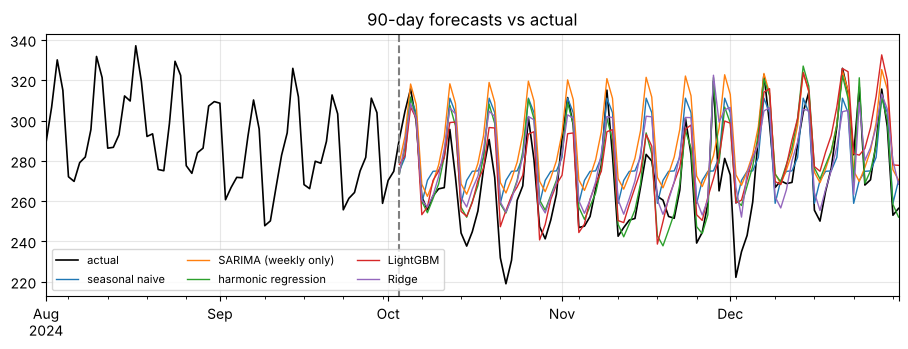

In [18]:
ax = sales["2024-08-01":].plot(c="k", lw=1.2, label="actual")
for name, f in [("seasonal naive", baselines["seasonal naive"]), ("SARIMA (weekly only)", sar_fc.predicted_mean),
                ("harmonic regression", harm_fc), ("LightGBM", gbm_fc), ("Ridge", ridge_fc)]:
    pd.Series(np.asarray(f), index=test.index).plot(ax=ax, lw=1, label=name)
ax.axvline(test.index[0], ls="--", c="gray"); plt.legend(fontsize=8, ncol=3); plt.title("90-day forecasts vs actual"); plt.show()

**Reading the results.**
- The models that beat seasonal naive all **know about the yearly calendar**, through day-of-year features (LightGBM, Ridge) or Fourier terms (harmonic regression). The models that only knew the weekly cycle overshoot all autumn. *Getting the seasonal structure right mattered far more than the choice of algorithm.*
- The lag-feature models feed their own predictions back in (recursive forecasting), so their errors compound over 90 days.
- Harmonic regression, which is just least squares with well-chosen features, wins. Simple models with the right features are hard to beat.
- A caution about trees: LightGBM **can't extrapolate a trend**. It only predicts values in the range it saw during training. It does well here because the trend is gentle and the horizon is short. With a strong trend or a long horizon, model the de-trended or differenced series, or add a linear trend component.

## 11. Walk-forward (time-series) cross-validation

One test window is one sample of luck. **Walk-forward validation** repeats the experiment: train on everything up to a cut-off, forecast the next block, move the cut-off forward, repeat.

```
fold 1: [train..........][test]
fold 2: [train...............][test]
fold 3: [train....................][test]
```

In [19]:
# 🐍 Pure Python walk-forward split
def walk_forward_python(n, n_folds=4, horizon=28, min_train=365):
    cuts = [n - horizon * (n_folds - i) for i in range(n_folds)]
    return [(list(range(0, c)), list(range(c, c + horizon))) for c in cuts if c >= min_train]

folds = walk_forward_python(len(sales))
from sklearn.model_selection import TimeSeriesSplit
sk_folds = list(TimeSeriesSplit(n_splits=4, test_size=28).split(sales))
print("our folds == sklearn TimeSeriesSplit:", all(f[1] == list(s[1]) for f, s in zip(folds, sk_folds)))

rows = []
for k, (tr_idx, te_idx) in enumerate(folds):
    tr_s, te_s = sales.iloc[tr_idx], sales.iloc[te_idx]
    sn = seasonal_naive_forecast(tr_s.tolist(), len(te_s))
    hwk = ExponentialSmoothing(tr_s, trend="add", seasonal="add", seasonal_periods=7).fit().forecast(len(te_s))
    hrk = harmonic_forecast(tr_s, te_s.index)
    scale = mase_scale(tr_s)
    rows.append({"fold": k + 1, "test starts": te_s.index[0].date(),
                 "seasonal naive MASE": np.mean(np.abs(te_s - sn)) / scale, "Holt-Winters MASE": np.mean(np.abs(te_s - hwk)) / scale,
                 "harmonic regression MASE": np.mean(np.abs(te_s - hrk)) / scale})
wf = pd.DataFrame(rows).set_index("fold"); wf.loc["mean"] = wf.mean(numeric_only=True); wf.round(3)

our folds == sklearn TimeSeriesSplit: True


,test starts,seasonal naive MASE,Holt-Winters MASE,harmonic regression MASE
fold,,,,
1,2024-09-11,0.787,0.942,0.520
2,2024-10-09,1.964,1.577,1.185
3,2024-11-06,1.252,1.071,0.799
4,2024-12-04,2.884,2.471,0.678
mean,NaN,1.722,1.516,0.796


## 12. Prediction intervals

A forecast without uncertainty is hard to act on ("order 300 units ± how many?"). Options:
- **Model-based:** ARIMA/state-space models give intervals directly.
- **Empirical:** collect your model's past forecast errors at each horizon and add their quantiles to the forecast (a simple form of **conformal prediction**).

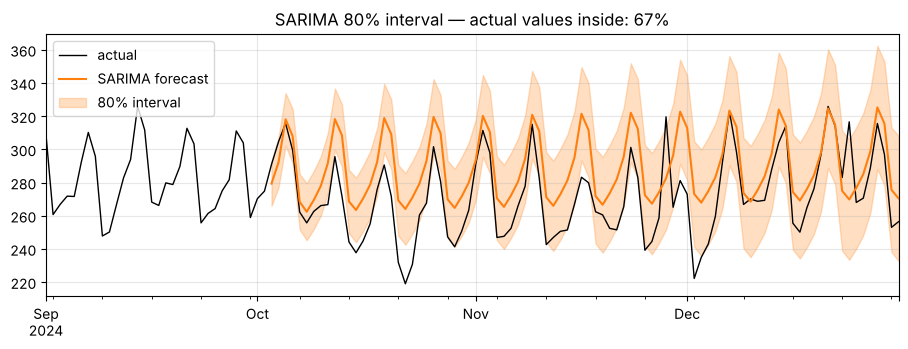

In [20]:
ci = sar_fc.conf_int(alpha=0.2)                                   # 80% interval from SARIMA
ax = sales["2024-09-01":].plot(c="k", lw=1, label="actual")
sar_fc.predicted_mean.plot(ax=ax, c="C1", label="SARIMA forecast")
ax.fill_between(test.index, ci.iloc[:, 0], ci.iloc[:, 1], color="C1", alpha=0.25, label="80% interval")
coverage = np.mean((test >= ci.iloc[:, 0]) & (test <= ci.iloc[:, 1]))
plt.legend(); plt.title(f"SARIMA 80% interval — actual values inside: {coverage:.0%}"); plt.show()

A model-based interval is only trustworthy **if the model is right**. SARIMA doesn't know about the yearly cycle, so its interval is centred too high all autumn and covers well under 80% of the actual values.

Empirical intervals rely on measuring *real* errors instead. Backtest the model many times (the cut-off moves through the past), record the errors at each horizon, and use their quantiles.

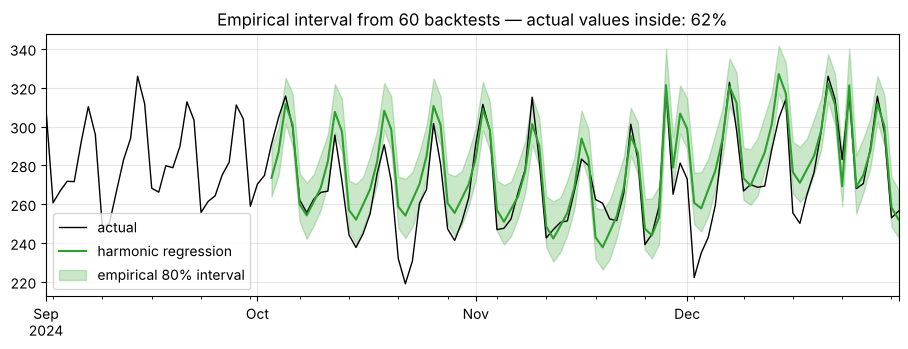

In [21]:
# 🔢 Empirical 80% intervals for harmonic regression, from backtest errors at each horizon (1..90 days)
H = test_days; errors = []
for cut in range(500, len(train) - H, 7):                       # weekly cut-offs through the training period
    tr_s, act = train.iloc[:cut], train.iloc[cut:cut + H]
    errors.append(act.to_numpy() - harmonic_forecast(tr_s, act.index).to_numpy())
errors = np.array(errors)                                       # (n_backtests, H)
lo, hi = np.quantile(errors, 0.1, axis=0), np.quantile(errors, 0.9, axis=0)
inside = (test.to_numpy() >= harm_fc.to_numpy() + lo) & (test.to_numpy() <= harm_fc.to_numpy() + hi)

ax = sales["2024-09-01":].plot(c="k", lw=1, label="actual")
harm_fc.plot(ax=ax, c="C2", label="harmonic regression")
ax.fill_between(test.index, harm_fc + lo, harm_fc + hi, color="C2", alpha=0.25, label="empirical 80% interval")
plt.legend(); plt.title(f"Empirical interval from {len(errors)} backtests — actual values inside: {inside.mean():.0%}"); plt.show()

Coverage is closer to the 80% target than SARIMA's but still short. That's a realistic result. The backtests overlap heavily, so 60 of them carry less information than it sounds. The test window is also a single autumn, and its errors are correlated from day to day: a bad week makes several days miss together. Treat any interval's stated coverage as approximate, and check it on fresh data once the model is live.

## 13. Pitfalls checklist
- **Never shuffle** before splitting; never fit scalers/encoders on future data.
- **Shift** rolling and expanding features so they end *before* the target time.
- Check the **feature is available at forecast time** (tomorrow's weather forecast: yes; tomorrow's actual weather: no).
- **Beat seasonal naive** before celebrating. Report MASE.
- Trees don't extrapolate trends — de-trend or difference first.
- Watch for **structural breaks** (a pandemic, a price change): old data may describe a world that no longer exists.
- Evaluate at the **horizon you'll actually use** (1-day-ahead skill says little about 90-day-ahead skill).

## Key takeaways
- Time series = trend + seasonality + autocorrelated remainder; decompose and look before modelling.
- Differencing removes trend/seasonality; ACF/PACF reveal the structure.
- Evaluate with time-ordered splits and walk-forward validation; compare with seasonal naive (MASE).
- **Model every seasonality.** A model told only about the weekly cycle can't anticipate the yearly one. Fourier terms handle long seasons cheaply.
- Classical models (Holt-Winters, SARIMA) are strong, cheap baselines for a single series. Harmonic regression handles multiple seasons. ML with lag features shines with many related series and extra features, as long as it's built without leakage.

## Exercises
1. Add a **promotions** feature: pick 40 random days, add +50 sales on them, and include the flag as a feature (it's known in advance). How much does the ML model improve?
2. Implement the **direct** strategy: for horizon h = 7, train a model using only lags ≥ 7 and compare with recursive at day 7.
3. Fit `STL` with `period=365` on the 7-day-smoothed series. Does it find the December peak?
4. Try `SARIMAX` orders (2,1,1)(1,1,1,7) and (1,0,1)(0,1,1,7). Which has the lowest AIC, and does it also have the lowest test MASE?

In [22]:
# Exercise 4 — solution
for order, sorder in [((1, 1, 1), (1, 1, 1, 7)), ((2, 1, 1), (1, 1, 1, 7)), ((1, 0, 1), (0, 1, 1, 7))]:
    mdl = SARIMAX(train, order=order, seasonal_order=sorder).fit(disp=False)
    f = mdl.forecast(test_days)
    print(f"SARIMA{order}{sorder}: AIC {mdl.aic:8.1f} | test MASE {np.mean(np.abs(test - f)) / SCALE:.3f}")
print("Lowest AIC and lowest test error often — but not always — agree.")

SARIMA(1, 1, 1)(1, 1, 1, 7): AIC   7558.9 | test MASE 1.695


SARIMA(2, 1, 1)(1, 1, 1, 7): AIC   7560.4 | test MASE 1.704


SARIMA(1, 0, 1)(0, 1, 1, 7): AIC   7597.8 | test MASE 1.287
Lowest AIC and lowest test error often — but not always — agree.


**Next:** [13 · Probability & Statistics for ML](13_probability_and_statistics.ipynb) — the maths of uncertainty, learned by simulation.

*Going deeper / interview prep:* `Probability_Statistics_Notes.md` §1.5 (Markov chains), Part 7 (regression inference) · `ML_System_Design_Notes.md` §7.5 (ETA prediction), §2.3 (point-in-time correctness) · code: `ml_from_scratch_part2.py` → `ARIMA`, `KalmanFilter`.